# HW1 Part C: Analysis and interpretation

i. **Infection peak:** the day on which $I(t)$ is maximal and the number infected then; discuss what determines the peak.

ii. **Basic reproduction number:** since $S$ and $I$ are counts,

$$R_0 = \frac{\beta N}{\gamma}$$

Compute it for the Part B parameters and explain how $R_0$ affects spread and control.

iii. **Epidemic dynamics:** describe $S$, $I$, $R$ over time; how many people are never infected by the end of the simulation?


In [1]:
import numpy as np

def forwardEuler(f, y0, t):
    # array of 0's to store inital value and all subsequent solved values
    y = np.zeros((len(t),) + np.shape(y0))
    # add initial condition to beginning of the array
    y[0] = y0
    # iterate over each time step
    for i in range(1, len(t)):
        #compute change in time 
        dt = t[i] - t[i-1]
        #previous time step solution plus time step change
        # multiplied by the derivative at the previous time step
        y[i] = y[i-1] + dt * f(y[i-1], t[i-1])
    return y


def sir_ders(y, beta, gamma):

    S, I, R = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return np.array([dSdt, dIdt, dRdt])

def sir_model(y0, t, beta, gamma):
    def f(y, t):
        return sir_ders(y, beta, gamma)
    return forwardEuler(f, y0, t)


In [2]:
import matplotlib.pyplot as plt

# intial conditions
N = 2000
S_0 = 1995
I_0 = 5
R_0 = 0
beta = 0.000125
gamma = 0.1

y0 = np.array([S_0, I_0, R_0])
# day 0 to day 160 with an Euler step of 0.1 day
t = np.arange(0, 160.1, 0.1)
solution = sir_model(y0, t, beta, gamma)
# transpose gives separate arrays for S, I, and R 
S, I, R = solution.T

# compute max of I and the day it happens
I_max = np.max(I)
I_max_day = t[np.argmax(I)]
print("Maximum number of infected individuals:", round(I_max, 1))
print("Day at which the maximum occurs:", I_max_day)
# S at the peak should equal gamma/beta = 800, where new infections per day = recoveries per day
print("S at the peak:", round(S[np.argmax(I)], 1), "  gamma/beta =", gamma / beta)
# people never infected = those still susceptible at the end of the simulation
print("Never infected (S at day 160):", round(S[-1], 1), "=", round(100 * S[-1] / N, 1), "% of N")
print("Ever infected (N - S at day 160):", round(N - S[-1], 1))
print("Day I first drops below 1 person:", t[np.argmax(I < 1)])

Maximum number of infected individuals: 470.5
Day at which the maximum occurs: 42.7
S at the peak: 799.9   gamma/beta = 800.0
Never infected (S at day 160): 212.8 = 10.6 % of N
Ever infected (N - S at day 160): 1787.2
Day I first drops below 1 person: 138.3


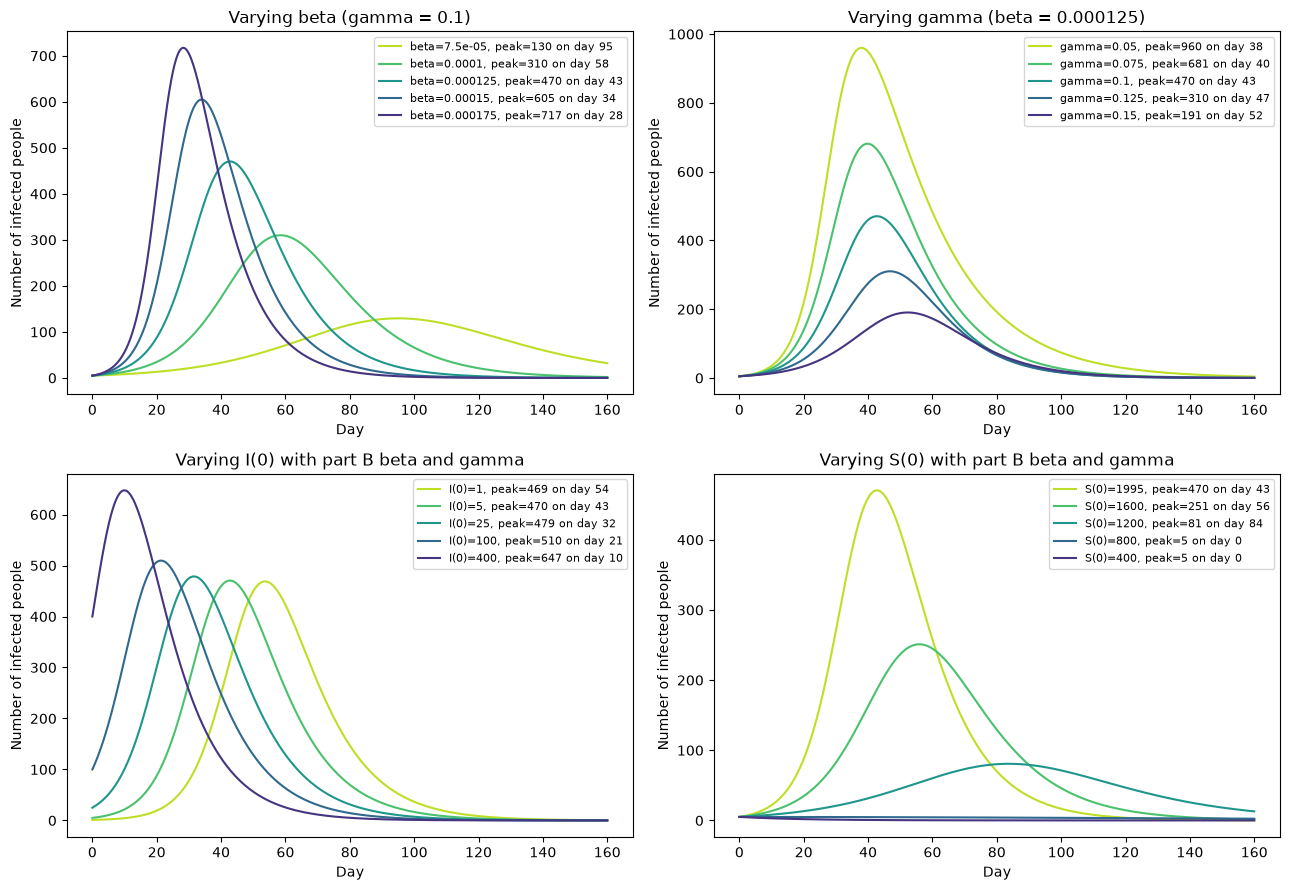

In [15]:
# vary beta, gamma, I(0) and S(0) one at a time around the part B values to show what determines the peak
# colors go from light to dark as the value increases
colors = plt.cm.viridis(np.linspace(0.9, 0.15, 5))

plt.figure(figsize=(13, 9))

# vary beta with gamma fixed at 0.1
beta_values = [0.000075, 0.0001, 0.000125, 0.00015, 0.000175]
plt.subplot(2, 2, 1)
for i, b in enumerate(beta_values):
    solution = sir_model(y0, t, b, gamma)
    S, I, R = solution.T
    I_max = np.max(I)
    I_max_day = t[np.argmax(I)]
    plt.plot(t, I, color=colors[i], label=f'beta={b}, peak={I_max:.0f} on day {I_max_day:.0f}')
plt.title('Varying beta (gamma = 0.1)')
plt.xlabel('Day')
plt.ylabel('Number of infected people')
plt.legend(fontsize=8)

# vary gamma with beta fixed at 0.000125
gamma_values = [0.05, 0.075, 0.1, 0.125, 0.15]
plt.subplot(2, 2, 2)
for i, g in enumerate(gamma_values):
    solution = sir_model(y0, t, beta, g)
    S, I, R = solution.T
    I_max = np.max(I)
    I_max_day = t[np.argmax(I)]
    plt.plot(t, I, color=colors[i], label=f'gamma={g}, peak={I_max:.0f} on day {I_max_day:.0f}')
plt.title('Varying gamma (beta = 0.000125)')
plt.xlabel('Day')
plt.ylabel('Number of infected people')
plt.legend(fontsize=8)

# vary I(0), N stays 2000 so S(0) = N - I(0)
I0_values = [1, 5, 25, 100, 400]
plt.subplot(2, 2, 3)
for i, i0 in enumerate(I0_values):
    y0_new = np.array([N - i0, i0, 0])
    solution = sir_model(y0_new, t, beta, gamma)
    S, I, R = solution.T
    I_max = np.max(I)
    I_max_day = t[np.argmax(I)]
    plt.plot(t, I, color=colors[i], label=f'I(0)={i0}, peak={I_max:.0f} on day {I_max_day:.0f}')
plt.title('Varying I(0) with part B beta and gamma')
plt.xlabel('Day')
plt.ylabel('Number of infected people')
plt.legend(fontsize=8)

# vary S(0), N stays 2000 so the rest start in R (already immune)
S0_values = [1995, 1600, 1200, 800, 400]
plt.subplot(2, 2, 4)
for i, s0 in enumerate(S0_values):
    y0_new = np.array([s0, 5, N - 5 - s0])
    solution = sir_model(y0_new, t, beta, gamma)
    S, I, R = solution.T
    I_max = np.max(I)
    I_max_day = t[np.argmax(I)]
    plt.plot(t, I, color=colors[i], label=f'S(0)={s0}, peak={I_max:.0f} on day {I_max_day:.0f}')
plt.title('Varying S(0) with part B beta and gamma')
plt.xlabel('Day')
plt.ylabel('Number of infected people')
plt.legend(fontsize=8)

plt.tight_layout()
plt.savefig('partC_peak_factors.png', dpi=150)
plt.show()

C.i

The maximum number of infected people is about 470, which occurs on day 43. At the peak the susceptible population is 800, which is gamma/beta, because I stops growing when the new infections per day beta*S*I equal the recoveries per day gamma*I, and dividing out I gives S = gamma/beta = 0.1/0.000125 = 800. So the peak is determined by how far S has to fall to reach gamma/beta and how fast it gets there. A larger beta means faster spread, so the peak comes earlier and is higher since S has to fall further before infections and recoveries balance and fewer people have had time to recover by then. A larger gamma drains the infected pool faster, so the peak is lower and comes later, and if gamma/beta is above S(0) there is no epidemic at all. The initial conditions also matter, as the 2x2 plot shows. More initial infected mostly makes the peak come earlier, and fewer initial susceptible makes the peak lower, down to no peak at all once S(0) is at or below 800.

In [ ]:
R0 = beta * N / gamma
print("Basic reproduction number (R0):", R0)

Basic reproduction number (R0): 2.5


C.ii

R0 = beta*N/gamma = 0.000125*2000/0.1 = 2.5, which is the average number of people one infected person infects when everyone is susceptible. It comes from each infected person infecting about beta*N people per day for an average of 1/gamma days. R0 = 1 is the dividing line, where an infected person on average infects one other person, so an R0 less than 1 means the epidemic is in decline and an R0 greater than 1 means it grows exponentially at first, and the larger R0 is the sooner and higher the peak since there is less time for the infected population to recover before it. Here R0 = 2.5 so each case leads to 2.5 new cases early on, which is why the epidemic takes off. To control the epidemic R0 has to be pushed below 1, either by lowering beta with social distancing, masks or quarantine, or by raising gamma with treatment that shortens the infectious period.

C.iii

At day 0, R(0) is 0 since we detect an epidemic when people become sick and nobody has recovered yet, and I(0) is small. Early on S barely changes while I grows exponentially at about beta*S(0) - gamma = 0.15 per day, and R grows behind I with a lag of about 1/gamma = 10 days. As I grows S drops faster and faster since the infection rate beta*S*I depends on both. I peaks at about 470 on day 43 when S has fallen to gamma/beta = 800, which is where new infections per day equal recoveries per day. After this the infection rate is less than the recovery rate because there are fewer people left to infect regardless of the transmission rate, so I decreases while R keeps increasing as the infected pool drains into it. By the end about 213 people (11% of N) are still susceptible and were never infected, and about 1787 were infected at some point. Not everyone gets infected because the epidemic ends when S falls too low for each case to replace itself, not when S reaches 0, so once I is near 0 the remaining susceptible people are safe even though they are not immune.